# Checkpoint 2

Estimating the location and extent of slow conduction regions in the heart is a classic inverse problem in cardiac electrophysiology. In this checkpoint, you will use mathematical modeling and computational techniques to estimate the position and radius of slow conduction areas from activation times annotated on electrogram measurements (see Checkpoint 1).

A key tool for this task is the **eikonal equation**, a simplified model of cardiac electrophysiology that describes activation time as a function of spatial coordinates. The eikonal formulation provides a fast and efficient way to reconstruct activation patterns, making it well suited for PDE-constrained optimization, physics-informed neural networks, and the generation of in silico datasets for scientific machine learning.

Using one of these approaches, you will estimate the location and size of slow conduction regions—by minimizing the discrepancy between simulated and observed activation times.
You will also account for unknown tissue properties, including conduction velocity and anisotropy, which play a crucial role in wavefront propagation. The velocity of slow conduction areas is assumed to be common across all patients and therefore needs to be estimated only once.


In [5]:
# imports

import numpy as np
import matplotlib.pyplot as plt


# Physics-based model implementation

Implemenatation of the algorithm presented in :

Sermesant, Maxime, et al. "An anisotropic multi-front fast marching method for real-time simulation of cardiac electrophysiology." Functional Imaging and Modeling of the Heart: 4th International Conference, FIHM 2007, Salt Lake City, UT, USA, June 7-9, 2007. Proceedings 4. Springer Berlin Heidelberg, 2007.

In [6]:
import numpy as np
import heapq

def anisotropic_FMM_GPT(
    x0, y0, t0,
    X, Y,
    speed_input,
    sigma_11, sigma_12, sigma_22,
    N_edge=None
):
    """
    Fast-marching style solver with anisotropy and spatially varying speed.

    Parameters
    ----------
    x0, y0 : float
        Initial source location.
    t0 : float
        Initial activation time.
    X, Y : 2D ndarray
        Grid coordinates.
    speed_input : float, callable, or 2D ndarray
        Can be:
        - a scalar: constant speed everywhere
        - a function: speed_input(x, y)
        - a 2D array with same shape as X, Y
    sigma_11, sigma_12, sigma_22 : float
        Components of the inverse of conductivity tensor.
    N_edge : int or None
        Optional. If None, inferred from grid shape.

    Returns
    -------
    T_final : 2D ndarray
        Arrival time map.
    """

    nrows, ncols = X.shape
    if N_edge is None:
        N_edge = nrows - 1

    INF = 1e4
    P = np.linspace(0.0, 1.0, 11)

    # nearest grid node to source
    j0 = np.abs(X[0, :] - x0).argmin()
    i0 = np.abs(Y[:, 0] - y0).argmin()

    T = np.full((nrows, ncols), INF, dtype=float)
    T_final = np.full((nrows, ncols), INF, dtype=float)

    T[i0, j0] = t0
    T_final[i0, j0] = t0

    known = np.zeros((nrows, ncols), dtype=bool)

    # min-heap of (arrival_time, i, j)
    heap = [(t0, i0, j0)]

    def get_speed(i, j, x, y):
        if callable(speed_input):
            val = speed_input(x, y)
        elif np.isscalar(speed_input):
            val = speed_input
        else:
            val = speed_input[i, j]

        if val <= 0:
            raise ValueError(f"Speed must be positive. Got {val} at ({i}, {j}).")
        return val

    def metric_dist(xa, ya, xb, yb, speed_val):
        dx = xa - xb
        dy = ya - yb
        return np.sqrt(
            sigma_11 * dx * dx +
            2.0 * sigma_12 * dx * dy +
            sigma_22 * dy * dy
        ) / speed_val

    def update_fun(
        T_xi, T_x, T_y,
        X_xi, X_x, X_y,
        Y_xi, Y_x, Y_y,
        flag_known,
        i_xi, j_xi
    ):
        speed_val = get_speed(i_xi, j_xi, X_xi, Y_xi)

        if flag_known:
            dx = P * (X_xi - X_x) + (1.0 - P) * (X_xi - X_y)
            dy = P * (Y_xi - Y_x) + (1.0 - P) * (Y_xi - Y_y)

            triangle_vals = (
                P * T_x + (1.0 - P) * T_y
                + np.sqrt(
                    sigma_11 * dx * dx +
                    2.0 * sigma_12 * dx * dy +
                    sigma_22 * dy * dy
                ) / speed_val
            )
            cand = triangle_vals.min()
        else:
            cand = T_x + metric_dist(X_xi, Y_xi, X_x, Y_x, speed_val)

        return min(T_xi, cand)

    # side nodes used for triangle updates
    side_map = {
        (-1,  0): [(-1, +1), (-1, -1)],  # north
        (+1,  0): [(+1, +1), (+1, -1)],  # south
        ( 0, -1): [(+1, -1), (-1, -1)],  # west
        ( 0, +1): [(+1, +1), (-1, +1)],  # east
    }

    while heap:
        t_sel, i_sel, j_sel = heapq.heappop(heap)

        # ignore stale entries
        if known[i_sel, j_sel]:
            continue
        if t_sel > T_final[i_sel, j_sel]:
            continue

        known[i_sel, j_sel] = True

        # visit 4-neighbors
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, +1)]:
            ni, nj = i_sel + di, j_sel + dj

            if not (0 <= ni < nrows and 0 <= nj < ncols):
                continue
            if known[ni, nj]:
                continue

            new_T = INF

            for sdi, sdj in side_map[(di, dj)]:
                si, sj = i_sel + sdi, j_sel + sdj

                if not (0 <= si < nrows and 0 <= sj < ncols):
                    continue

                new_T = update_fun(
                    T_xi=new_T,
                    T_x=T_final[i_sel, j_sel],
                    T_y=T_final[si, sj],
                    X_xi=X[ni, nj], X_x=X[i_sel, j_sel], X_y=X[si, sj],
                    Y_xi=Y[ni, nj], Y_x=Y[i_sel, j_sel], Y_y=Y[si, sj],
                    flag_known=known[si, sj],
                    i_xi=ni, j_xi=nj
                )

            if new_T < T_final[ni, nj]:
                T[ni, nj] = new_T
                T_final[ni, nj] = new_T
                heapq.heappush(heap, (new_T, ni, nj))

    return T_final

# Eikonal equation

Let us consider the Eikonal model: find T(x,y)

\begin{aligned}
  & 80 \sqrt{ \nabla T(x,y) D \nabla T(x,y)} = 1  \,, \quad (x,y) \in [-2,2] \times [-2,2]\,,\\
  & u(x,y) = t_0,t_1  \,, \qquad \qquad \qquad \qquad \qquad x=x_0,x_1,y=y_0,y_1 \,, \\
\end{aligned}

where 
\begin{aligned}
D = 1\ \vec{b} \otimes \vec{b} + \frac{1}{a_{ratio}}  \ \vec{a} \otimes \vec{a},
\end{aligned}
being $ \vec{b} $ the given fiber orientation and $ \vec{a} $ the given cross-fiber orientation (orthogonal to $ \vec{b}$).

The unknown parameters of the problem are: 
- conduction velocity (tissue property common to all the patients),
- anisotropy ratio $a_{ratio}$ (tissue property common to all the patients),
- the slow conduction positions $(x_{SC},y_{SC})$ and its radius $r_{SC}$.

In [7]:
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0,2.0,401), np.linspace(-2.0,2.0,401))

x0 = -1.5
y0 = -1

theta_fiber = 0
a_ratio = 5

theta0 = np.pi/2 - theta_fiber
a = np.array([np.cos(theta0), np.sin(theta0)]).T
b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
print(D)

D_inv = np.linalg.inv(D)
sigma_11 = D_inv[0][0]
sigma_12 = D_inv[0][1]
sigma_21 = D_inv[1][0]
sigma_22 = D_inv[1][1]

xc, yc = 0.5, 0.5
r = 0.5

speed_field = lambda x, y: 20.0 if (x - xc)**2 + (y - yc)**2 <= r**2 else 80.0

activation_time = anisotropic_FMM_GPT( x0 , y0 , 0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )




[[1.0000000e+00 1.2246468e-17]
 [1.2246468e-17 2.0000000e-01]]


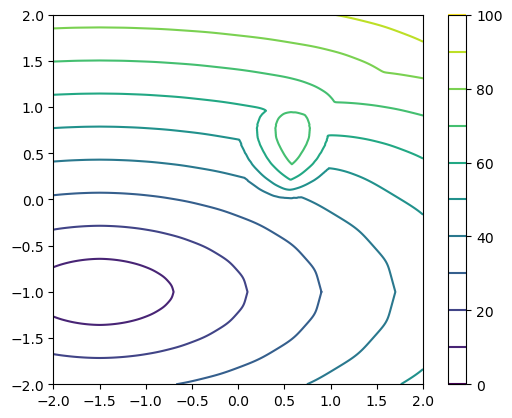

In [8]:

plt.contour(X_mesh, Y_mesh, activation_time*1000 , 10) 
plt.gca().set_aspect(1)
plt.colorbar()

In [ ]:
N_samples = 1

np.random.seed(32)

measurements_dataset = []
groundtruth_dataset = []

for i_sample in range(N_samples):

    x0 = np.random.uniform(low=1.5,high=1.5)
    y0 = np.random.uniform(low=-1.5,high=1.5)
    x1 = np.random.uniform(low=1.5,high=1.5)
    y1 = np.random.uniform(low=-1.5,high=1.5)
    theta_fiber = 0.0
    a_ratio = np.random.uniform(low=1,high=9)

    theta0 = np.pi/2 - theta_fiber
    a = np.array([np.cos(theta0), np.sin(theta0)]).T
    b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T

    D = ( (1/a_ratio)*np.tensordot( a, a,  axes=0) + np.tensordot( b, b,  axes=0)  )
    print(D)

    D_inv = np.linalg.inv(D)
    sigma_11 = D_inv[0][0]
    sigma_12 = D_inv[0][1]
    sigma_21 = D_inv[1][0]
    sigma_22 = D_inv[1][1]

    # compute activation time
    activation_time = anisotropic_FMM_GPT( x0 , y0 , 0.0, X_mesh, Y_mesh, speed_field, sigma_11,sigma_12, sigma_22, N_edge=200 )

    # rescaling in ms
    activation_time = activation_time*1e3

    # measurements location
    Spline_spacing = [0.5, 0.7, 1.3, 1.5]
    Angles_spacing =  [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5 ]
    
    index_extracted = []
    x_meas = []
    y_meas = []
    time_meas = []

    for i in range(4):
        #print(i)
        for j in range(5):
            #print(j)
            MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]) )**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]) )**2
            [i_sel, j_sel] = np.unravel_index(MeasMat.argmin(), MeasMat.shape) 
            index_extracted.append(i_sel)
            x_meas.append(X_mesh[i_sel,j_sel])
            y_meas.append(Y_mesh[i_sel,j_sel])
            time_meas.append(activation_time[i_sel,j_sel])

    measurements_dataset.append( [ x_meas, y_meas, time_meas ] )
    groundtruth_dataset.append([activation_time])

<>:11: SyntaxWarning: invalid escape sequence '\ '
<>:11: SyntaxWarning: invalid escape sequence '\ '
C:\Users\simon\AppData\Local\Temp\ipykernel_13180\1316113712.py:11: SyntaxWarning: invalid escape sequence '\ '
  |  .  .  . /-----------------\  .  .  . |



      +-------------------------------------+
    ( |              WWWWWWWW               | )
     /|                                     |\
      | -----[ O ]-------+-------[ O ]----- |
      |                  |                  |
      |                 _|                  |
      |                                     |
      |  .  .  . /-----------------\  .  .  . |
      |   .  .  .  .  .  .  .  .  .  .  .   |
      +-------------------------------------+
    
[[1.00000000e+00 8.88280440e-18]
 [8.88280440e-18 1.45067205e-01]]


In [ ]:
plt.figure(1)
plt.scatter( x_meas, y_meas, c=time_meas, vmin= 0, vmax=np.max(activation_time) )
plt.contour(X_mesh, Y_mesh, activation_time , 10)
plt.gca().set_aspect(1)
plt.colorbar()

# Checkpoint 2

Implement your algorithm to process the traces of the 20 unipolar electrogram signals and identify the center and radius of the slow conduction region.

The algorithm must return the following outputs:

1. **slow conduction center** 
2. **slow conduction radius**

Therefore output should be in the following form:
[x_SC,y_SC,r_SC] 

Provide your algorithm's implementation in this notebook usign the signature defined below.

In [ ]:
# load data
signals = np.load('checkpoint2dataset.npy')

# select event to be display
ind_event = 0

signals_event = signals[ind_event,:,:]

In [ ]:
# select a spline (options: 0,1,2,3,4)
ind_spline = 0
# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

In [ ]:
# known starting points (to test your algorithm)
# Note that a rescaling with respect to the center is needed
impulse_sites = np.load('checkpoint2FocalPoints.npy') -2.0
[x0,y0] = impulse_sites[0][0]
[x1,y1] = impulse_sites[0][1]

# t_0, t_1 can be extracted from the file: "checkpoint2starting.npy"

In [ ]:
import numpy as np
from scipy.optimize import minimize
from scipy.signal import argrelextrema, savgol_filter
import warnings
warnings.filterwarnings("ignore")

# ==========================================
# 0. FUNZIONE ESTRAZIONE TEMPI (DA CP1)
# ==========================================
def GroupSolutionCP1(signals_event):
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    
    for i in range(n_sensors):
        ds = np.gradient(sig_filtered[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            selected.sort()

        row_time = [None, None]
        for j in range(min(len(selected), 2)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

    return timings

# ==========================================
# 1. SETUP SPAZIALE
# ==========================================
X_mesh, Y_mesh = np.meshgrid(np.linspace(-2.0, 2.0, 401), np.linspace(-2.0, 2.0, 401))
Spline_spacing = [0.5, 0.7, 1.3, 1.5]
Angles_spacing = [np.pi/10.0+0, np.pi/10.0+(2)*np.pi/5, np.pi/10.0+(4)*np.pi/5, np.pi/10.0+(6)*np.pi/5, np.pi/10.0+(8)*np.pi/5]

meas_indices = []
for i in range(4):
    for j in range(5):
        MeasMat = (X_mesh - Spline_spacing[i]*np.cos(Angles_spacing[j]))**2 + (Y_mesh - Spline_spacing[i]*np.sin(Angles_spacing[j]))**2
        i_sel, j_sel = np.unravel_index(MeasMat.argmin(), MeasMat.shape)
        meas_indices.append((i_sel, j_sel))

# ==========================================
# 2. CARICAMENTO DATI UFFICIALI
# ==========================================
signals = np.load('checkpoint2dataset.npy') 
impulse_sites = np.load('checkpoint2FocalPoints.npy') - 2.0 
starting_times = np.load('checkpoint2starting.npy') 

# INSERISCI I DATI REALI forniti per l'anisotropia
a_ratios_training = [5.0, 4.0, 6.0, 3.5, 5.5] # DA SOSTITUIRE

reference_targets = [
    [-0.407, 0.299, 0.578],
    [0.81, 0.113, 0.394],
    [-0.816, -0.686, 0.274],
    [0.197, -0.242, 0.042],
    [0.647, -0.69, 0.244]
] #

# ==========================================
# 3. PRE-ESTRAZIONE TEMPI MISURATI (2 BATTITI)
# ==========================================
measured_times_beat1 = []
measured_times_beat2 = []

for idx_event in range(5):
    raw_timings = GroupSolutionCP1(signals[idx_event, :, :])
    
    # Estraiamo i tempi del primo e del secondo battito
    t_beat1 = np.array([t[0] for t in raw_timings], dtype=float)
    t_beat2 = np.array([t[1] for t in raw_timings], dtype=float)
    
    measured_times_beat1.append(t_beat1)
    measured_times_beat2.append(t_beat2)

# ==========================================
# 4. FUNZIONE OBIETTIVO DA MINIMIZZARE
# ==========================================
def objective_velocities(velocities):
    v_base, v_slow = velocities
    total_mse = 0.0
    
    for idx in range(5):
        xc, yc, r = reference_targets[idx]
        a_ratio = a_ratios_training[idx]
        
        # Costruzione tensore di diffusione specifico del paziente
        theta_fiber = 0.0
        theta0 = np.pi/2 - theta_fiber
        a = np.array([np.cos(theta0), np.sin(theta0)]).T
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T
        D = ((1/a_ratio)*np.tensordot(a, a, axes=0) + np.tensordot(b, b, axes=0))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0][0], D_inv[0][1], D_inv[1][1]
        
        # Campo di velocità comune a entrambi i battiti dello stesso paziente
        speed_field = lambda x, y: v_slow if (x - xc)**2 + (y - yc)**2 <= r**2 else v_base
        
        # --- SIMULAZIONE BATTITO 1 ---
        x0, y0 = impulse_sites[idx][0]
        t0 = starting_times[idx][0]/1000
        
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh, Y_mesh, speed_field, 
            sigma_11, sigma_12, sigma_22, N_edge=200
        ) * 1000.0 #
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices])
        meas_times1 = measured_times_beat1[idx]
        
        valid_mask1 = ~np.isnan(meas_times1)
        if np.any(valid_mask1):
            total_mse += np.mean((sim_times1[valid_mask1] - meas_times1[valid_mask1])**2)
            
        # --- SIMULAZIONE BATTITO 2 ---
        x1, y1 = impulse_sites[idx][1]
        t1 = starting_times[idx][1]/1000
        
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh, Y_mesh, speed_field, 
            sigma_11, sigma_12, sigma_22, N_edge=200
        ) * 1000.0 #
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices])
        meas_times2 = measured_times_beat2[idx]
        
        valid_mask2 = ~np.isnan(meas_times2)
        if np.any(valid_mask2):
            total_mse += np.mean((sim_times2[valid_mask2] - meas_times2[valid_mask2])**2)
        
    return total_mse

# ==========================================
# 5. AVVIO OTTIMIZZAZIONE
# ==========================================
initial_guess = [80.0, 20.0] 
bounds = [(40.0, 150.0), (5.0, 40.0)] 

print("Inizio calibrazione delle velocità (su 2 battiti per paziente)...")
result = minimize(objective_velocities, initial_guess, method='L-BFGS-B', bounds=bounds)

if result.success:
    print(f"\n✅ Ottimizzazione convergente!")
    print(f"Velocità tessuto sano (v_base): {result.x[0]:.2f}")
    print(f"Velocità tessuto lento (v_slow): {result.x[1]:.2f}")
else:
    print("\n❌ L'ottimizzatore non ha trovato un minimo:", result.message)

In [ ]:
# 6. SALVATAGGIO DELLE VELOCITÀ STIMATE
# ==========================================
# Estraiamo le velocità in modo automatico dall'ottimizzazione precedente
if result.success:
    EST_V_BASE = result.x[0]
    EST_V_SLOW = result.x[1]

### signature of the function ###

In [ ]:
# ==========================================
# 7. FUNZIONE FINALE (FASE 2)
# ==========================================
def GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1):
    """
    Funzione finale per la stima del sito di slow conduction e dell'anisotropia.
    Ritorna esclusivamente: [x_SC, y_SC, r_SC] come richiesto.
    """
    # Richiamiamo le velocità calcolate automaticamente dal blocco precedente
    global EST_V_BASE, EST_V_SLOW
    
    # --- 1. ESTRAZIONE TEMPI MISURATI DAL PAZIENTE ---
    raw_timings = GroupSolutionCP1(signals_event)
    
    # Estraiamo i tempi, gestendo l'eventualità in cui manchi il secondo battito
    meas_beat1 = np.array([t[0] if len(t) > 0 else np.nan for t in raw_timings], dtype=float)
    meas_beat2 = np.array([t[1] if len(t) > 1 else np.nan for t in raw_timings], dtype=float)
    
    # --- 2. ALLINEAMENTO CRONOLOGICO DEGLI IMPULSI INPUT ---
    # Convertiamo i tempi in secondi per la Fast Marching come hai giustamente fatto tu prima
    t0 = t_0 / 1000
    t1 = t_1 / 1000        

    # --- 3. FUNZIONE DI OTTIMIZZAZIONE PAZIENTE-SPECIFICA ---
    def patient_cost(params):
        # Cerchiamo 4 parametri: x_SC, y_SC, r_SC e a_ratio
        xc, yc, r, a_ratio = params
        total_mse = 0.0
        
        # Costruzione del tensore di diffusione con l'anisotropia ipotizzata
        theta_fiber = 0.0
        theta0 = np.pi/2 - theta_fiber
        a = np.array([np.cos(theta0), np.sin(theta0)]).T
        b = np.array([np.cos(theta0-np.pi/2), np.sin(theta0-np.pi/2)]).T
        D = ((1/a_ratio)*np.tensordot(a, a, axes=0) + np.tensordot(b, b, axes=0))
        D_inv = np.linalg.inv(D)
        sigma_11, sigma_12, sigma_22 = D_inv[0][0], D_inv[0][1], D_inv[1][1]
        
        # Campo di velocità che usa le costanti automatiche
        speed_field = lambda x, y: EST_V_SLOW if (x - xc)**2 + (y - yc)**2 <= r**2 else EST_V_BASE
        
        # Simulazione e calcolo errore BATTITO A
        sim_beat1 = anisotropic_FMM_GPT(
            x0, y0, t0, X_mesh, Y_mesh, speed_field, 
            sigma_11, sigma_12, sigma_22, N_edge=200
        ) * 1000.0 
        
        sim_times1 = np.array([sim_beat1[i, j] for i, j in meas_indices])
        
        mask1 = ~np.isnan(meas_beat1)
        if np.any(mask1):
            total_mse += np.mean((sim_times1[mask1] - meas_beat1[mask1])**2)
            
        # Simulazione e calcolo errore BATTITO B
        sim_beat2 = anisotropic_FMM_GPT(
            x1, y1, t1, X_mesh, Y_mesh, speed_field, 
            sigma_11, sigma_12, sigma_22, N_edge=200
        ) * 1000.0 
        
        sim_times2 = np.array([sim_beat2[i, j] for i, j in meas_indices])
        
        mask2 = ~np.isnan(meas_beat2)
        if np.any(mask2):
            total_mse += np.mean((sim_times2[mask2] - meas_beat2[mask2])**2)
            
        return total_mse

    # --- 4. ESECUZIONE RICERCA (GRADIENT-FREE) ---
    initial_guess = [0.0, 0.0, 0.5, 5.0]
    
    # Limiti: griglia [-2, 2], raggio [0.05, 1.5], anisotropia [1, 10]
    bounds = [(-2.0, 2.0), (-2.0, 2.0), (0.05, 1.5), (1.0, 10.0)]
    
    # Nelder-Mead come raccomandato.
    res_patient = minimize(patient_cost, initial_guess, method='Nelder-Mead', bounds=bounds)
    
    # --- 5. FORMATTAZIONE OUTPUT FINALE ---
    x_SC, y_SC, r_SC, a_ratio_stimato = res_patient.x
    
    # Restituiamo solo i tre valori richiesti, scartando l'anisotropia
    return [x_SC, y_SC, r_SC]

In [ ]:
# ==========================================
# TEST RAPIDO SUL PRIMO PAZIENTE (SCENARIO 1)
# ==========================================

print("=== AVVIO TEST SINGOLO (Scenario 1) ===\n")

# Indice 0 corrisponde al primo scenario
idx = 0

# 1. Estrazione dati
signals_event = signals[idx, :, :]
x_0, y_0 = impulse_sites[idx][0]
x_1, y_1 = impulse_sites[idx][1]
t_0 = starting_times[idx][0]
t_1 = starting_times[idx][1]
true_x, true_y, true_r = reference_targets[idx]

# 2. Avvio predizione (vedrai apparire la barra di caricamento qua sotto)
print("Avvio simulazione. Elaborazione in corso...\n")
predicted_target = GroupSolutionCP2(signals_event, x_0, y_0, t_0, x_1, y_1, t_1)
pred_x, pred_y, pred_r = predicted_target

# 3. Calcolo e stampa degli errori
center_err = np.sqrt((pred_x - true_x)**2 + (pred_y - true_y)**2)
r_err = abs(pred_r - true_r)

print(f"\n✅ Test Completato!")
print(f"Target Reale  : Centro [{true_x:6.3f}, {true_y:6.3f}], Raggio: {true_r:5.3f}")
print(f"Target Stimato: Centro [{pred_x:6.3f}, {pred_y:6.3f}], Raggio: {pred_r:5.3f}")
print(f"Errore Centro : {center_err:.4f} cm")
print(f"Errore Raggio : {r_err:.4f} cm")